In [1]:
import P04_Parser

from igor2 import binarywave
import numpy as np

import os
import hyperspy.api as hs
import matplotlib.pyplot as plt
from pathlib import Path

def load_ibw_swept_as_kmap(file):
    """Swept (2D) .ibw cut -> Kmap with 3 identical theta_y slices, so P04_Parser plotting works."""
    wave = binarywave.load(file)["wave"]
    data = np.array(wave["wData"], dtype=float)     # (energy, angle)
    sfa = wave["wave_header"]["sfA"]
    sfb = wave["wave_header"]["sfB"]
    energy = sfb[0] + sfa[0] * np.arange(data.shape[0])
    theta = sfb[1] + sfa[1] * np.arange(data.shape[1])
    data_map = np.repeat(data[:, :, np.newaxis], 3, axis=2)
    return P04_Parser.Kmap(data_map, energy, theta, np.array([-1, 0, 1]))

In [7]:
data = load_ibw_swept_as_kmap(
    r"T:\Beamtimes\MaxIV\Oct_26\raw\FeSi_2B_49eV_LV_temp_series\FeSi_2B_hv_49_LV_GX_20K_0001Swept.ibw"
)


roi = data.get_rois_in_grid(plot=False)[0]
asd = data.get_EDC_inside(roi)

file_dir = r"T:\Beamtimes\MaxIV\Oct_26\raw\FeSi_2B_49eV_LV_temp_series"
files = os.listdir(file_dir)

files_names_fesi = [f for f in files if f.endswith(".ibw") and "testing" not in f and not f.startswith("TaFoil")]
files = [os.path.join(file_dir, f) for f in files_names_fesi]


labels = {f: f[20:-14] for f in files_names_fesi} #[20:-14] for FeSi and [19:-17] for TaFoil
labels

{'FeSi_2B_hv_49_LV_GX_100K_0001Swept.ibw': '100K',
 'FeSi_2B_hv_49_LV_GX_100K_down_0001Swept.ibw': '100K_down',
 'FeSi_2B_hv_49_LV_GX_200K_0001Swept.ibw': '200K',
 'FeSi_2B_hv_49_LV_GX_20K_0001Swept.ibw': '20K',
 'FeSi_2B_hv_49_LV_GX_20K_down_0001Swept.ibw': '20K_down',
 'FeSi_2B_hv_49_LV_GX_60K_0001Swept.ibw': '60K',
 'FeSi_2B_hv_49_LV_GX_60K_down_0001Swept.ibw': '60K_down'}

In [32]:
raw_dir = r"T:\Beamtimes\MaxIV\Oct_26\raw"

directories = [dir for dir in os.listdir(raw_dir) if "." not in dir]

Ta_foil_files = []

for dir in directories:
    Ta_foil_files.append([f for f in os.listdir(os.path.join(raw_dir, dir)) if f.endswith(".ibw") and "test" not in f and (f.startswith("TaFoil") or f.startswith("Ta_foil")) and not f.startswith("TaFoil_XPS")])
    
Ta_foil_files

[[],
 [],
 [],
 ['TaFoil_swept_hv_24_LH_200K_0001Swept_24.ibw',
  'TaFoil_swept_hv_24_LH_200K_0002Swept_24.ibw',
  'TaFoil_swept_hv_24_LH_20K_down_0001Swept_24.ibw',
  'Ta_foil_swept_hv_24_LH_20K_0001Swept_24.ibw'],
 ['TaFoil_swept_hv_49_LV_GX_20K_0001Swept.ibw',
  'TaFoil_swept_hv_49_LV_GX_20K_down_0001Swept.ibw',
  'TaFoil_swept_hv_49_LV_GX_40K_0001Swept.ibw',
  'TaFoil_swept_hv_49_LV_GX_40K_down_0001Swept.ibw',
  'TaFoil_swept_hv_49_LV_GX_60K_0001Swept.ibw'],
 ['TaFoil_2A_swept_hv_84_LV_GM_0001Swept_84.ibw',
  'TaFoil_swept_hv_125_LH_GM_0001Swept_125.ibw',
  'TaFoil_swept_hv_125_LV_GM_0001Swept_125.ibw'],
 ['TaFoil_hv_49_LV_GX_100K_0001Swept_Ta.ibw',
  'TaFoil_hv_49_LV_GX_100K_down_0001Swept_Ta.ibw',
  'TaFoil_hv_49_LV_GX_200K_0001Swept_Ta.ibw',
  'TaFoil_hv_49_LV_GX_20K_0001Swept.ibw',
  'TaFoil_hv_49_LV_GX_20K_0002Swept_Ta.ibw',
  'TaFoil_hv_49_LV_GX_20K_down_0001Swept_Ta.ibw',
  'TaFoil_hv_49_LV_GX_60K_down_0001Swept_Ta.ibw'],
 [],
 [],
 ['TaFoil_swept_hv_125_LH_GX_20K_0001Swept_

In [ ]:
# Ta_foil_files[10]
# os.path.join("T:\\Beamtimes\\MaxIV\\Oct_26\\raw", directories[10], Ta_foil_files[10][0])


{'TaFoil_swept_hv_24_LH_200K_0001Swept_24.ibw': '200K',
 'TaFoil_swept_hv_24_LH_200K_0002Swept_24.ibw': '200K',
 'TaFoil_swept_hv_24_LH_20K_down_0001Swept_24.ibw': '20Kdown',
 'Ta_foil_swept_hv_24_LH_20K_0001Swept_24.ibw': '20K'}

{'TaFoil_swept_hv_24_LH_200K_0001Swept_24.ibw': '200K', 'TaFoil_swept_hv_24_LH_200K_0002Swept_24.ibw': '200K', 'TaFoil_swept_hv_24_LH_20K_down_0001Swept_24.ibw': '20Kdown', 'Ta_foil_swept_hv_24_LH_20K_0001Swept_24.ibw': '20K'}


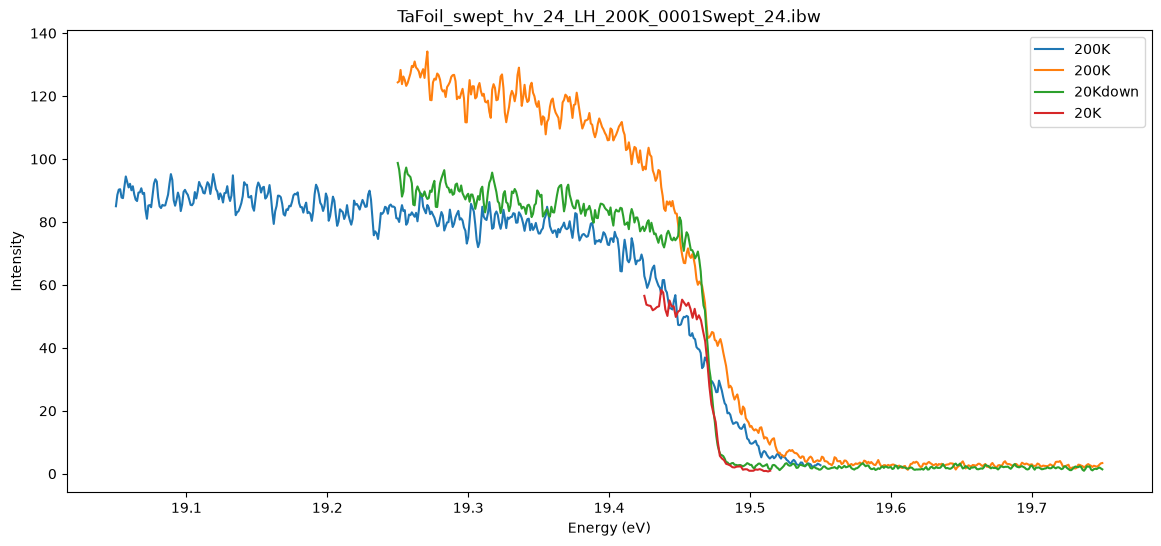

{'TaFoil_swept_hv_49_LV_GX_20K_0001Swept.ibw': '20K', 'TaFoil_swept_hv_49_LV_GX_20K_down_0001Swept.ibw': '20Kdown', 'TaFoil_swept_hv_49_LV_GX_40K_0001Swept.ibw': '40K', 'TaFoil_swept_hv_49_LV_GX_40K_down_0001Swept.ibw': '40Kdown', 'TaFoil_swept_hv_49_LV_GX_60K_0001Swept.ibw': '60K'}


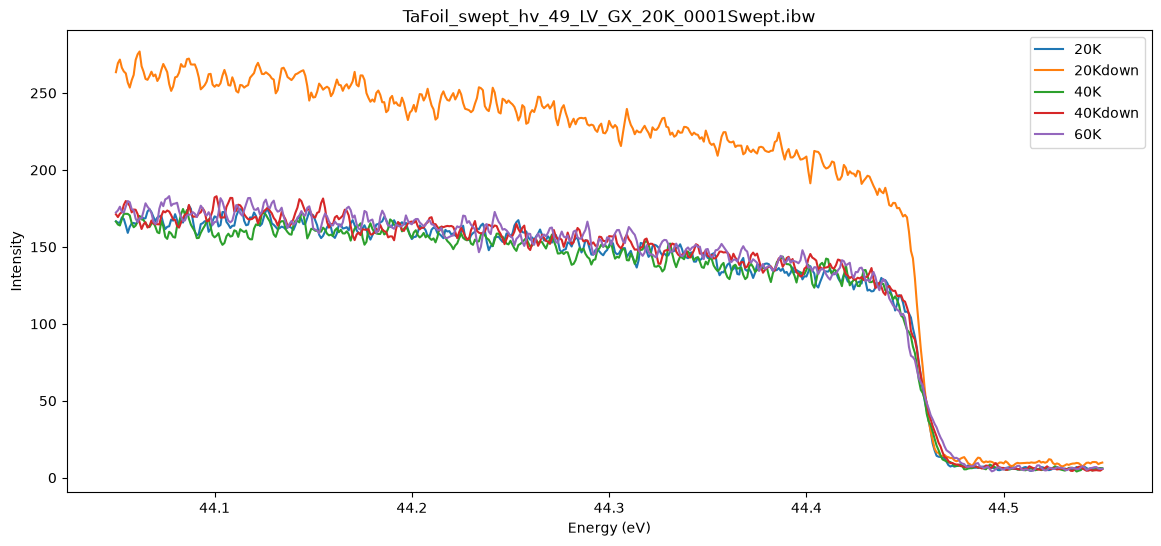

{'TaFoil_hv_49_LV_GX_100K_0001Swept_Ta.ibw': '100K', 'TaFoil_hv_49_LV_GX_100K_down_0001Swept_Ta.ibw': '100Kdown', 'TaFoil_hv_49_LV_GX_200K_0001Swept_Ta.ibw': '200K', 'TaFoil_hv_49_LV_GX_20K_0001Swept.ibw': '20K', 'TaFoil_hv_49_LV_GX_20K_0002Swept_Ta.ibw': '20K', 'TaFoil_hv_49_LV_GX_20K_down_0001Swept_Ta.ibw': '20Kdown', 'TaFoil_hv_49_LV_GX_60K_down_0001Swept_Ta.ibw': '60Kdown'}


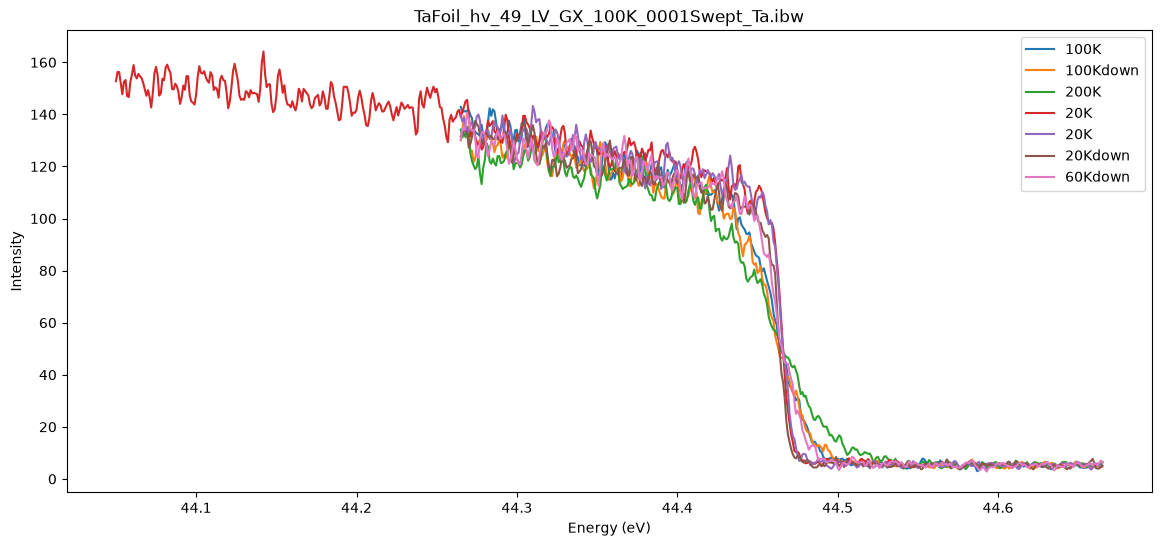

{'TaFoil_swept_hv_125_LH_GX_20K_0001Swept_125.ibw': '20K', 'TaFoil_swept_hv_125_LH_GX_20K_down_0001Swept_125.ibw': '20Kdown', 'TaFoil_swept_hv_125_LH_GX_60K_0001Swept_125.ibw': '60K', 'TaFoil_swept_hv_125_LH_MR_20K_0001Swept_125.ibw': '20K', 'TaFoil_swept_hv_125_LV_MR_20K_0001Swept_125.ibw': '20K'}


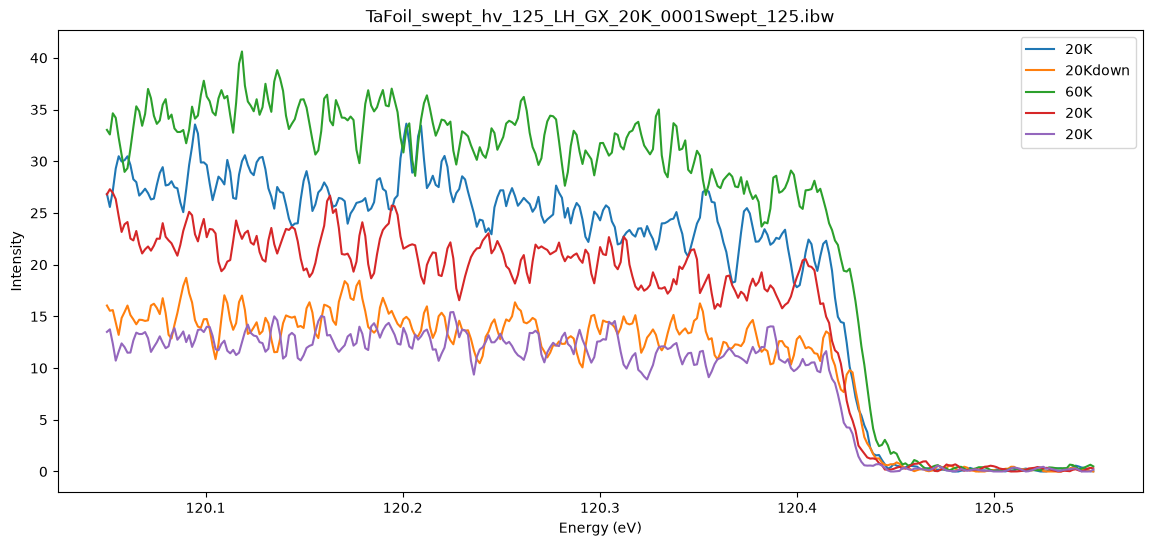

{'TaFoil_swept_hv_84_LV_20K_0001Swept_84.ibw': '20K', 'TaFoil_swept_hv_84_LV_20K_0002Swept_84.ibw': '20K', 'TaFoil_swept_hv_84_LV_40K_0001Swept_84.ibw': '40K', 'TaFoil_swept_hv_84_LV_60K_0001Swept_84.ibw': '60K'}


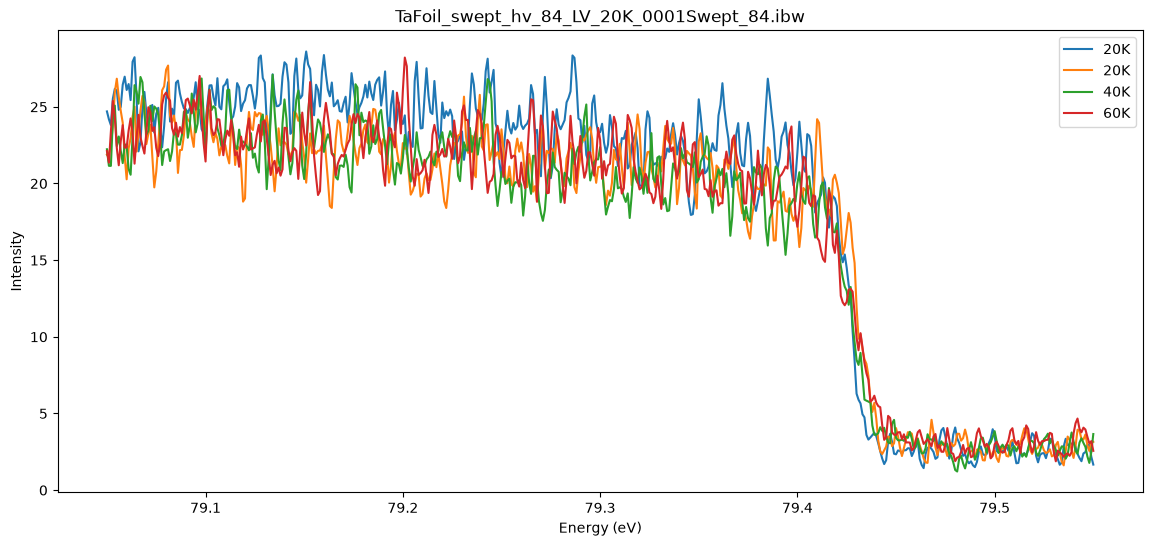

In [88]:

first_roi = None
for dir_idx in [3, 4, 6, 9, 10]:

    fig, ax = plt.subplots(figsize=(14, 6))
    curves = []

# dir_idx = 6
    file_dir = "T:\\Beamtimes\\MaxIV\\Oct_26\\raw"
    labels = {f: "".join([x for x in f.split("_") if x.endswith("K") or "down" in x]) for f in Ta_foil_files[dir_idx]} #[20:-14] for FeSi and [19:-17] for TaFoil
    print(labels)
    files = [os.path.join(file_dir, directories[dir_idx], f) for f in Ta_foil_files[dir_idx]]


    for file in files:
        data = load_ibw_swept_as_kmap(file)

        if first_roi is None:
            first_roi = data.get_rois_in_grid(plot=False)[0]

        roi = hs.roi.CircleROI(
            cx=0,
            cy=0,
            r=1,
        )

        edc = data.get_EDC_inside(roi)
        energy = edc.axes_manager[0].axis
        intensity = np.asarray(edc.data).squeeze()
        label = labels[Path(file).name]

        curves.append((label, energy, intensity))
        ax.plot(energy, intensity, label=label)

    # Find intersections for every pair of curves
    intersections = []

    for i in range(len(curves)):
        for j in range(i + 1, len(curves)):
            label_i, energy_i, intensity_i = curves[i]
            label_j, energy_j, intensity_j = curves[j]

            # Use the overlapping energy range
            energy_min = max(energy_i.min(), energy_j.min())
            energy_max = min(energy_i.max(), energy_j.max())
            energy_common = np.linspace(energy_min, energy_max, 5000)

            intensity_i_common = np.interp(
                energy_common, energy_i, intensity_i
            )
            intensity_j_common = np.interp(
                energy_common, energy_j, intensity_j
            )

            difference = intensity_i_common - intensity_j_common
            crossing_indices = np.where(
                difference[:-1] * difference[1:] <= 0
            )[0]

            for index in crossing_indices:
                x1 = energy_common[index]
                x2 = energy_common[index + 1]
                y1 = difference[index]
                y2 = difference[index + 1]

                if y2 != y1:
                    crossing_energy = x1 - y1 * (x2 - x1) / (y2 - y1)
                    crossing_intensity = np.interp(
                        crossing_energy, energy_common, intensity_i_common
                    )
                    if crossing_intensity > 400 and crossing_intensity < 1500: #400 and 1500 for FeSi and 30 and 80 for TaFoil
                        intersections.append(
                            [label_i, label_j, crossing_energy, crossing_intensity]
                        )

                        ax.plot(
                            crossing_energy,
                            crossing_intensity,
                            "ko",
                            markersize=4,
                        )

    # for label_i, label_j, energy, intensity in intersections:
    #     print(
    #         f"{label_i} crosses {label_j} at "
    #         f"energy={energy:.6g}, intensity={intensity:.6g}"
    #     )

    ax.set_xlabel("Energy (eV)")
    ax.set_ylabel("Intensity")
    ax.legend()
    plt.title(list(labels.keys())[0])
    plt.show()